In [ ]:
import pandas as pd
import numpy as np
from sklearn.datasets import fetch_california_housing
cal_housing = fetch_california_housing(as_frame=True)
df=cal_housing.frame

In [ ]:
#Data preprocessing
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [ ]:
df.shape

(20640, 9)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [ ]:
df.isnull().sum()

,0
MedInc,0
HouseAge,0
AveRooms,0
AveBedrms,0
Population,0
AveOccup,0
Latitude,0
Longitude,0
MedHouseVal,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


In [ ]:
#Separate x and y
x=df.drop('MedHouseVal',axis=1)
y=df['MedHouseVal']

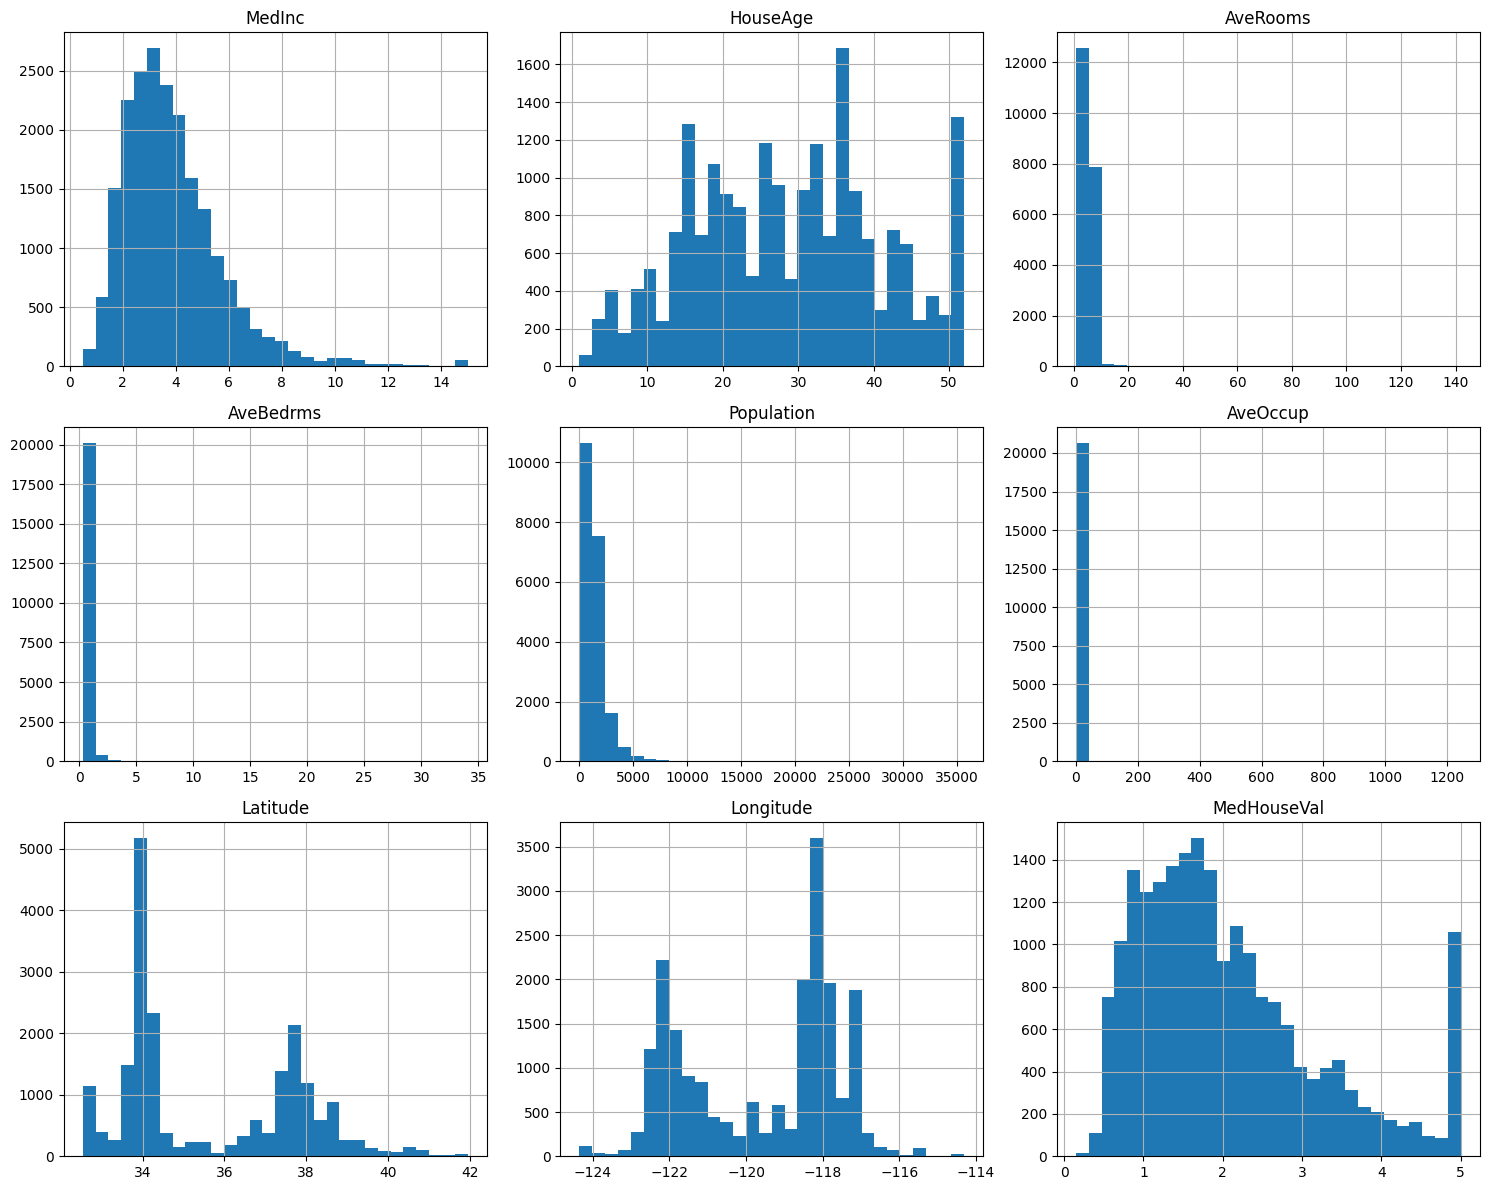

In [ ]:
#EDA-Distribution of features-plot
import matplotlib.pyplot as plt
import seaborn as sns
df.hist(figsize=(15,12),bins=30)
plt.tight_layout()
plt.show()


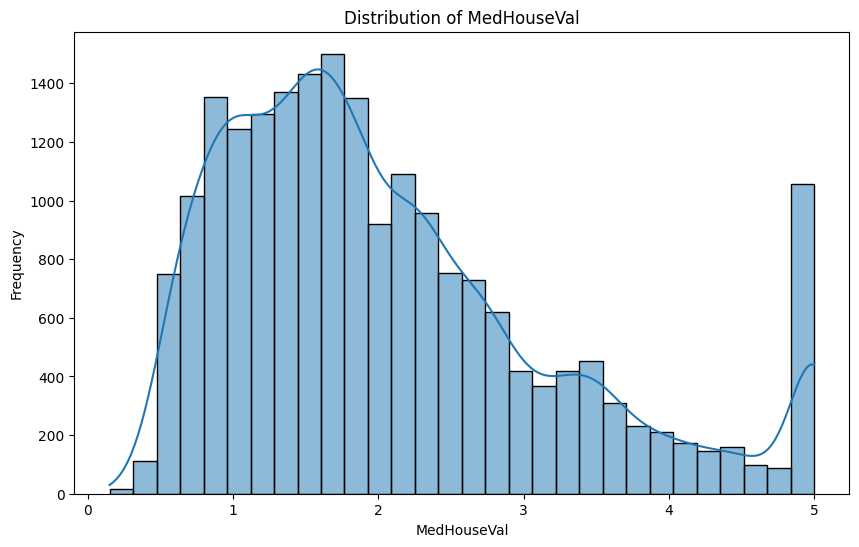

In [ ]:
#Distribution of target variable
plt.figure(figsize=(10,6))
sns.histplot(df['MedHouseVal'],bins=30,kde=True)
plt.xlabel('MedHouseVal')
plt.ylabel('Frequency')
plt.title('Distribution of MedHouseVal')
plt.show()

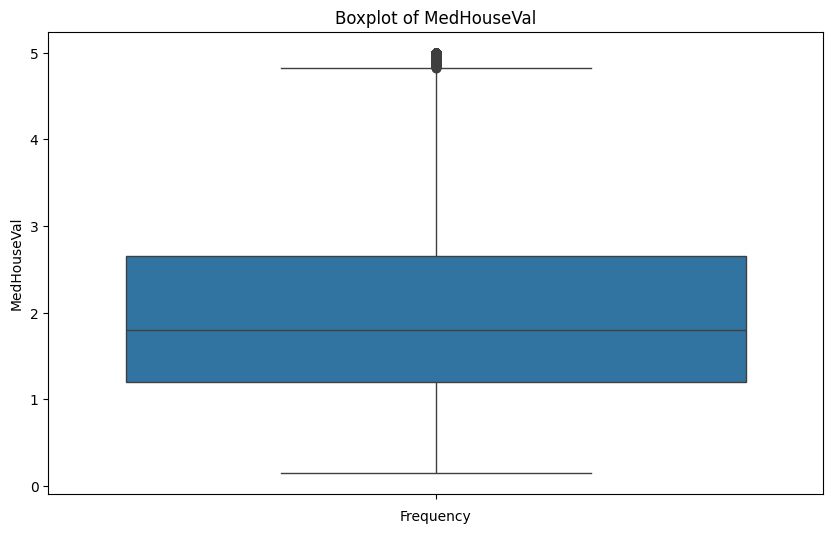

In [ ]:
#Boxplot of target
plt.figure(figsize=(10,6))
sns.boxplot(df['MedHouseVal'])
plt.xlabel('Frequency')
plt.ylabel('MedHouseVal')
plt.title('Boxplot of MedHouseVal')
plt.show()


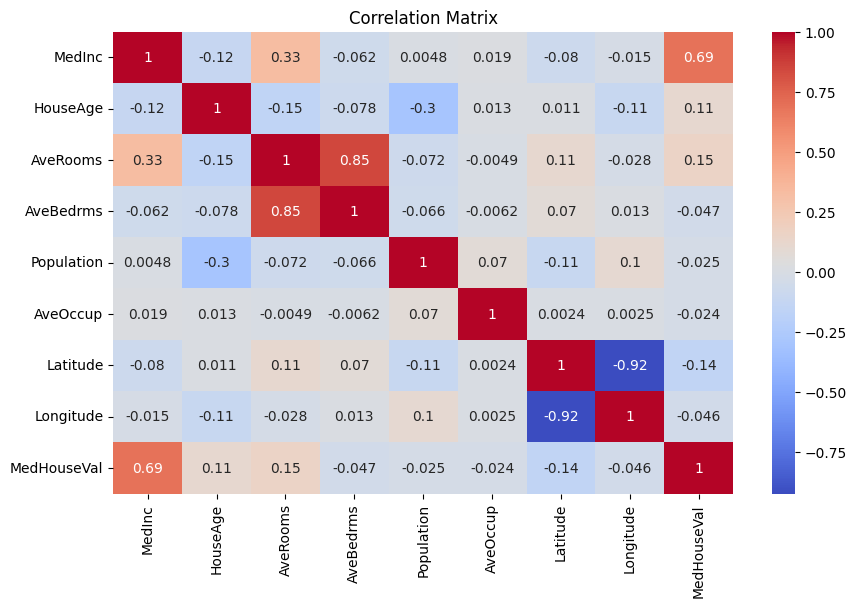

In [ ]:
#Correlation Matrix
plt.figure(figsize=(10,6))
sns.heatmap(df.corr(),annot=True,cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

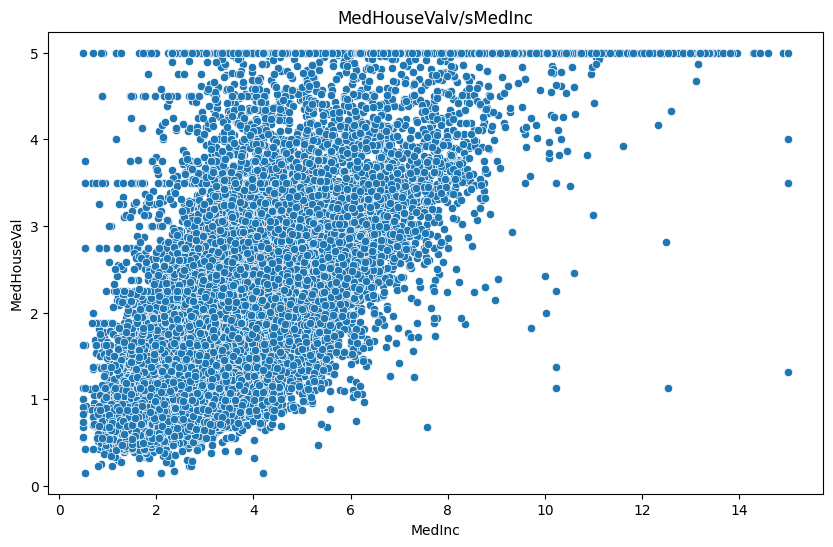

In [ ]:
#Features v/s Target
plt.figure(figsize=(10,6))
sns.scatterplot(x='MedInc',y='MedHouseVal',data=df)
plt.xlabel('MedInc')
plt.ylabel('MedHouseVal')
plt.title("MedHouseValv/sMedInc")
plt.show()



In [ ]:
df.columns

Index(['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup',
       'Latitude', 'Longitude', 'MedHouseVal'],
      dtype='object')

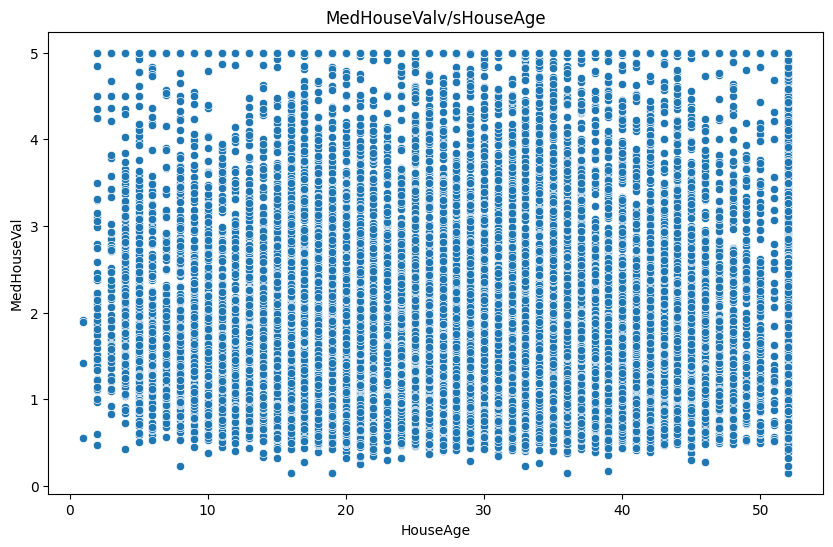

In [ ]:
plt.figure(figsize=(10,6))
sns.scatterplot(x='HouseAge',y='MedHouseVal',data=df)
plt.xlabel('HouseAge')
plt.ylabel('MedHouseVal')
plt.title("MedHouseValv/sHouseAge")
plt.show()


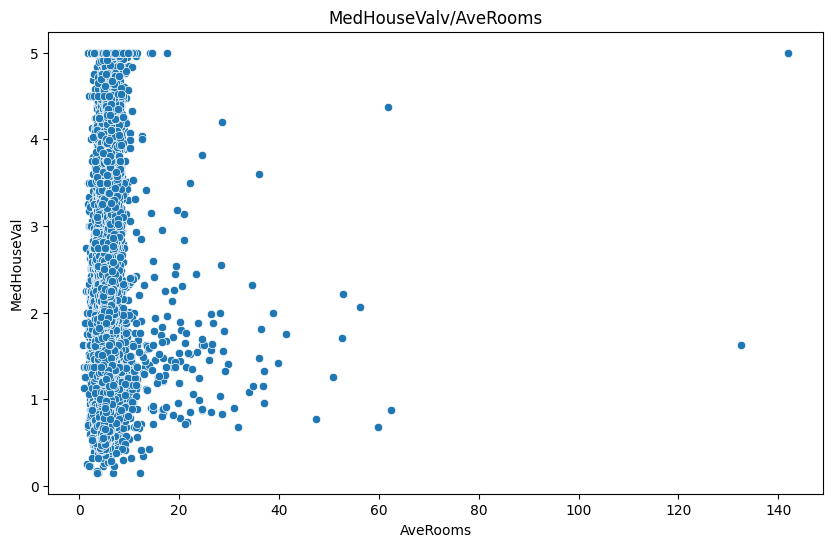

In [ ]:
plt.figure(figsize=(10,6))
sns.scatterplot(x='AveRooms',y='MedHouseVal',data=df)
plt.xlabel('AveRooms')
plt.ylabel('MedHouseVal')
plt.title("MedHouseValv/AveRooms")
plt.show()

In [ ]:
#Train-Test split
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.15,random_state=42)


In [ ]:
#Train Validation Split
x_train,x_val,y_train,y_val=train_test_split(x_train,y_train,test_size=0.1765,random_state=42)

In [ ]:
#Scailing of data
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
x_train_scaled=scaler.fit_transform(x_train)
x_test_scaled=scaler.transform(x_test)
x_val_scaled=scaler.transform(x_val)


In [ ]:
#Building Model-ANN
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
model=Sequential()
model.add(Dense(64,activation="relu",input_shape=(x_train.shape[1],)))
model.add(Dense(32,activation="relu"))
model.add(Dense(1))



/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
#Compile
model.compile(optimizer="adam",loss="mse",metrics=["mae"])

In [ ]:
#Model Training
history=model.fit(x_train,y_train,epochs=50,batch_size=32,validation_data=(x_val,y_val))

Epoch 1/50
452/452 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 1607.8199 - mae: 9.3837 - val_loss: 3.4517 - val_mae: 1.2250
Epoch 2/50
452/452 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 4.4507 - mae: 1.3079 - val_loss: 2.4463 - val_mae: 1.1822
Epoch 3/50
452/452 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 2.5930 - mae: 1.1438 - val_loss: 1.5006 - val_mae: 0.9497
Epoch 4/50
452/452 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 3.1733 - mae: 1.1804 - val_loss: 1.3111 - val_mae: 0.8140
Epoch 5/50
452/452 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 1.8593 - mae: 0.9828 - val_loss: 1.1539 - val_mae: 0.8563
Epoch 6/50
452/452 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 5.7001 - mae: 1.2209 - val_loss: 1.3319 - val_mae: 0.9464
Epoch 7/50
452/452 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 6.8149 - mae: 1.4404 - val_loss: 0.9505 - val_mae: 0.7583
Epoch 8/50
452/452 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 14.5219 - mae: 2.1125 - val_loss: 4.7489 - val_mae: 1.6638
Epoch 9/50
452/452 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step 

In [ ]:
#Prediction
y_pred=model.predict(x_test_scaled)


97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


Evaluation-1

In [ ]:
mse=mean_squared_error(y_test,y_pred)
mae=mean_absolute_error(y_test,y_pred)
r2=r2_score(y_test,y_pred)
print('Mean Squared Error:',mse)
print('Mean Absolute Error:',mae)
print('R2 Score:',r2)

Mean Squared Error: 5.487082079451385
Mean Absolute Error: 2.120181390485363
R2 Score: -3.186989186537291


In [ ]:
from tensorflow.keras.callbacks import EarlyStopping
early_stop=EarlyStopping(monitor="val_loss",patience=3,restore_best_weights=True)

In [ ]:
model=Sequential()
model.add(Dense(128,activation='relu',input_shape=(x_train.shape[1],)))
model.add(Dense(64,activation="relu"))
model.add(Dense(32,activation='relu'))
model.add(Dense(1))


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
model.compile(optimizer='adam',loss='mse',metrics=['mae'])

In [ ]:
history=model.fit(x_train_scaled,y_train,epochs=100,batch_size=32,validation_data=(x_val_scaled,y_val),callbacks=[early_stop])


Epoch 1/100
452/452 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - loss: 0.6679 - mae: 0.5532 - val_loss: 0.3781 - val_mae: 0.4445
Epoch 2/100
452/452 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3846 - mae: 0.4353 - val_loss: 0.3445 - val_mae: 0.4231
Epoch 3/100
452/452 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3549 - mae: 0.4175 - val_loss: 0.3326 - val_mae: 0.4016
Epoch 4/100
452/452 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3347 - mae: 0.4055 - val_loss: 0.3360 - val_mae: 0.4144
Epoch 5/100
452/452 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.3316 - mae: 0.3978 - val_loss: 0.3112 - val_mae: 0.3868
Epoch 6/100
452/452 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3086 - mae: 0.3854 - val_loss: 0.3409 - val_mae: 0.4257
Epoch 7/100
452/452 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3019 - mae: 0.3790 - val_loss: 0.3098 - val_mae: 0.3928
Epoch 8/100
452/452 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.3014 - mae: 0.3767 - val_loss: 0.3087 - val_mae: 0.3733
Epoch 9/100
452/452 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/

In [ ]:
#prediction
y_pred=model.predict(x_test_scaled)

97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


Evaluation-2

In [ ]:
mse=mean_squared_error(y_test,y_pred)
mae=mean_absolute_error(y_test,y_pred)
r2=r2_score(y_test,y_pred)
print('Mean Squared Error:',mse)
print('Mean Absolute Error:',mae)
print('R2 Score:',r2)

Mean Squared Error: 0.2815505941666932
Mean Absolute Error: 0.3644503051269948
R2 Score: 0.7851591654417244


In [ ]:
model=Sequential()
model.add(Dense(128,activation="relu",input_shape=(x_train.shape[1],)))
model.add(Dense(64,activation="tanh"))
model.add(Dense(32,activation="tanh"))
model.add(Dense(1))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
model.compile(optimizer='adam',loss='mse',metrics=['mae'])

In [ ]:
history=model.fit(x_train_scaled,y_train,epochs=100,batch_size=64,validation_data=(x_val_scaled,y_val),callbacks=[early_stop])


Epoch 1/100
226/226 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 0.6255 - mae: 0.5629 - val_loss: 0.4466 - val_mae: 0.4653
Epoch 2/100
226/226 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.3983 - mae: 0.4497 - val_loss: 0.3631 - val_mae: 0.4304
Epoch 3/100
226/226 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.3671 - mae: 0.4286 - val_loss: 0.3470 - val_mae: 0.4129


In [ ]:
#predictions3
y_pred=model.predict(x_test_scaled)

97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


Evaluation-3

In [ ]:
mse=mean_squared_error(y_test,y_pred)
mae=mean_absolute_error(y_test,y_pred)
r2=r2_score(y_test,y_pred)
print('Mean Squared Error:',mse)
print('Mean Absolute Error:',mae)
print('R2 Score:',r2)

Mean Squared Error: 0.4706090016476128
Mean Absolute Error: 0.4713847560998692
R2 Score: 0.6408956942042545


  

1.   MSE1 Mean Squared Error: 5.5758689259816165
2.   MAE2Mean Absolute Error: 2.103197113677865
     R2SCORE1 R2 Score: -3.2547391419682468

     AFTER IMPROVISING THE MODEL


1.   Mean Squared Error: 0.2777045153107414
     Mean Absolute Error: 0.3557967091079492
     R2 Score: 0.7880939658232872

     

*   ADDING LAYERS TO ANN MODEL
*   INTRODUCE EARLY STOPPING
    CHANGES EPOCHS 50 to 100 the values considerably improved .errors reduced r2 score became positive and close to 1.



*   changing activation function "relu" to tanh r2 score slightly reduced and errors also slightly increased.


-change activation function(relu and tanh)
-change layer(adding layer)
-change batch size
-change epochs
-set early stop
-add dropouts




